In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [2]:
img = cv2.imread('Image1.jpg')
print(type(img))

<class 'numpy.ndarray'>


In [3]:
def contrast_stretch(img):
    img_float = img.astype(np.float32)
    min_val = img_float.min()
    max_val = img_float.max()
    if max_val == min_val:
        return np.zeros_like(img, dtype=np.uint8)
    stretched =  255.0* (img_float - min_val) / (max_val - min_val)
    return np.clip(stretched,0,256).astype(np.uint8)

In [4]:
def equalize_hist_manual(img):
    hist = np.bincount(img.ravel(),minlength=256)
    cdf = hist.cumsum()
    nonzero_cdf = cdf[cdf > 0]

    if len(nonzero_cdf) == 0:
        return np.zeros_like(img), np.arange(256, dtype=np.uint8)

    cdf_min = nonzero_cdf[0]
    total = img.size

    if total == cdf_min:
        return img.copy(), np.arange(256, dtype=np.uint8)

    lut = np.round((cdf - cdf_min) * 255 / (total - cdf_min))
    lut = np.clip(lut, 0, 255).astype(np.uint8)
    return lut[img]

In [5]:
def plot_hist(imgs,titles):
    plt.figure(figsize=(6*len(imgs),5))
    for idx,(img,title) in enumerate(zip(imgs,titles)):
        plt.subplot(1,len(imgs),idx+1)
        if img.ndim == 2:
            hist = np.bincount(img.ravel(),minlength=256)
            plt.plot(hist,color='black',label='BLACK')
        else:
            for idx, color in enumerate(['red','green','blue']):
                hist = cv2.calcHist([img],[idx],None, [256], [0,256])
                plt.plot(hist,color=color,label=color.upper())
        plt.title(title)
        plt.xlabel(f'Pixel')
        plt.ylabel('Instensity')
        plt.legend()
    plt.show()

In [6]:
def show_images(imgs,titles):
    plt.figure(figsize=(4*len(imgs),5))
    for idx, (img,title) in enumerate(zip(imgs,titles),start =1):
        plt.subplot(1,len(imgs),idx)
        if img.ndim == 2:
            plt.imshow(img,cmap ='gray')
        else:
            plt.imshow(img)
        plt.title(title)
        plt.axis('off')
    plt.show()

In [7]:
def gamma_transform(img, gamma):
    img_float = img.astype(np.float32) / 255.0 
    corrected = 255.0 * (img_float ** gamma)
    return np.clip(corrected, 0, 255).astype(np.uint8)

In [8]:
img = cv2.cvtColor(img,cv2.COLOR_BGR2RGB)

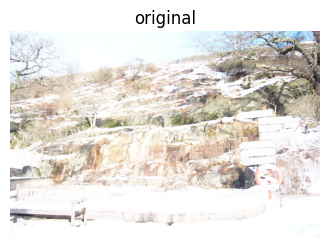

In [9]:
show_images([img],['original'])

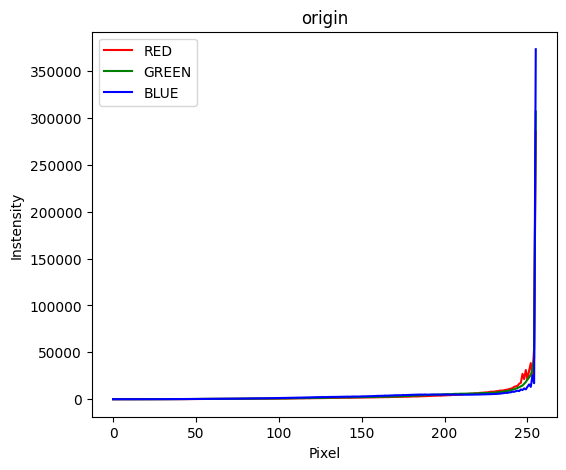

In [10]:
plot_hist([img],['origin'])

In [11]:
contrast = contrast_stretch(img)
equl = equalize_hist_manual(img)

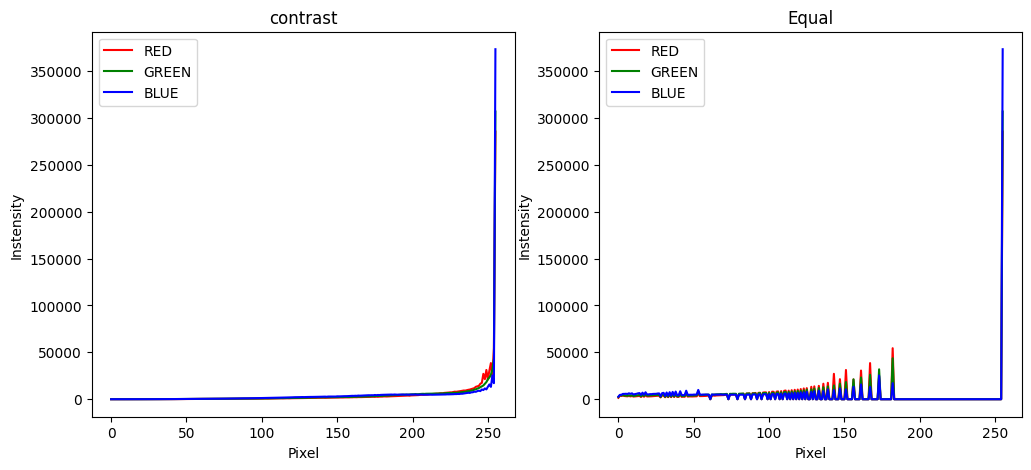

In [12]:
plot_hist([contrast,equl],["contrast",'Equal'])

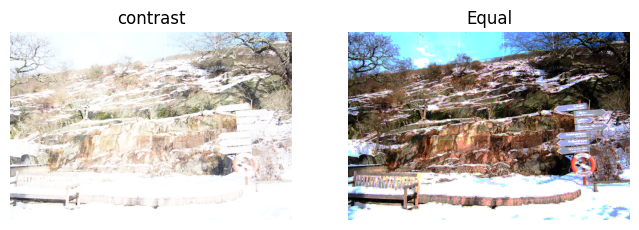

In [13]:
show_images([contrast,equl],["contrast",'Equal'])

In [29]:
r,g,b = cv2.split(equl)
r = gamma_transform(r,1.1)
rgb = cv2.merge([r,g,b])

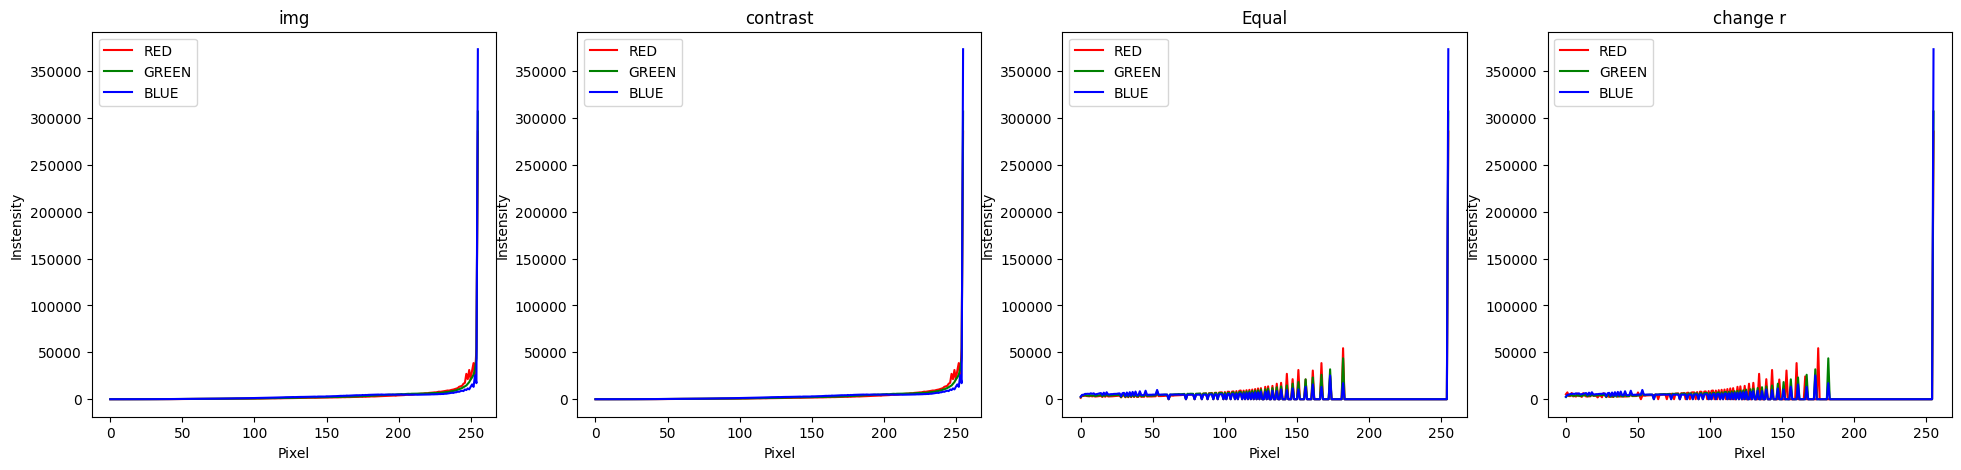

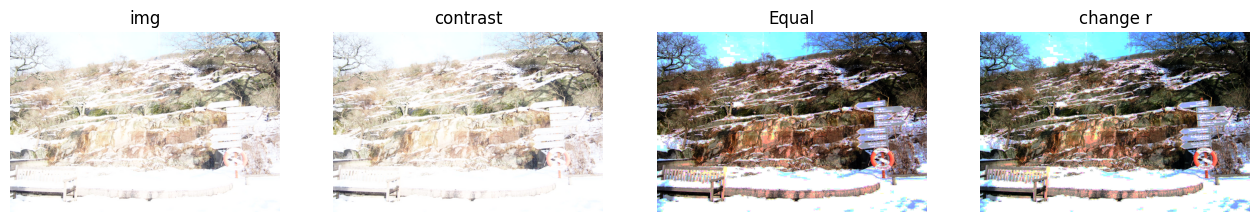

In [31]:
plot_hist([img,contrast,equl,rgb],['img',"contrast",'Equal','change r'])
show_images([img, contrast,equl,rgb],['img',"contrast",'Equal','change r'])